# Parte teórica

Classifique as afirmações em Verdadeiro ou Falso, justifique as afirmativas falsas

1 - A etapa de **quantização** em um processo de compressão de dados consiste em aumentar a aleatoriedade das informações.

**Resposta:** Falso, a etapa de quantização consiste em mapear um conjunto grande de valores e conseguir reduzi-lo para um menor, comprimindo-o.

2 - Compresão do tipo fractal consiste em encontrar áreas similares ao redor de uma região de domínio.

**Resposta:** Verdadeiro.

3 - Histogramas de duas imagens distintas não serão nunca iguais.

**Resposta:** Falso, uma vez que o histograma mede apenas a frequência de cada tom de cor presente na imagem, é perfeitamente possível que duas imagens distintas possuam o mesmo histograma.

4 - O método RLE de compressão de dados sempre gera um resultado com menor quantidade de dados (comprimido).

**Resposta:** Falso, em cenários desfavoráveis, como quando cada letra aparece apenas uma vez, o RLE pode acabar fazendo com que o resultado seja maior que o dado original.

5 - No contexto de áudios, frequência de amostragem é a frequência com que são captadas amostras do audio analógico para gerar um digital.

**Resposta:** Verdadeiro.

# Parte prática

## Material de apoio

### Importações

```
import moviepy.editor as mpe
import moviepy as mp
import numpy as np
import matplotlib.pyplot as plt
```

### Histograma
```
def histogram_gray(img):
    (l, c) = img.shape
    histogram = np.zeros(256, dtype=np.int32)

    for i in range(l):
        for j in range(c):
            intensity = img[i, j]
            histogram[intensity] += 1
            
    return histogram

def show_histogram(img):
    histogram_r = histogram_gray(img[:, :, 0])
    histogram_g = histogram_gray(img[:, :, 1])
    histogram_b = histogram_gray(img[:, :, 2])
    
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 1, 1)
    plt.bar(range(256), histogram_r, color='red', alpha=0.5, label='R')
    plt.bar(range(256), histogram_g, color='green', alpha=0.5, label='G')
    plt.bar(range(256), histogram_b, color='blue', alpha=0.5, label='B')
    plt.legend()
    plt.show()
```

### Manipulação de imagens

```
(l,c,p) = img.shape
plt.imshow(imagem)
plt.show()
```

### Forçando uma imagem de uma página para 3 páginas
```
  imagem_3p = np.zeros(shape=(l,c,3),dtype=np.uint8)
  imagem_3p[:,:, 0] = frame_1p
  imagem_3p[:,:, 1] = frame_1p
  imagem_3p[:,:, 2] = frame_1p
```

### Detecção de bordas
```
    def detectar_bordas(frame, threshold=30):
    l, c, p = frame.shape
    imagem_grey = np.average(frame, axis=2).astype(np.float64)
   
    # O argumento 'append' precisa receber uma estrutura compatível com as dimensões do array.
    # Usar um valor escalar como 'append=255' em arrays 2D pode quebrar dependendo da versão do Numpy.
    # Correção segura usando np.pad ou mantendo o append correto em uma dimensão:
    abs_tg_c = np.abs(np.diff(imagem_grey, axis=0, append=imagem_grey[-1:, :]))
    abs_tg_l = np.abs(np.diff(imagem_grey, axis=1, append=imagem_grey[:, -1:]))
    abs_tg = np.sqrt(abs_tg_c ** 2 + abs_tg_l ** 2)

    imagem_border = np.zeros(shape=(l, c), dtype=np.uint8)
    imagem_border[abs_tg > threshold] = 255
    
    # Se for usar essa função dentro do MoviePy, lembre-se que ele exige retorno em 3 canais (RGB):
    imagem_border_3p = np.stack([imagem_border]*3, axis=-1)
    return imagem_border_3p
```

### Manipulação de vídeo
```
# Carregar o vídeo
video = mp.VideoFileClip("video.mp4")

# Pegar frames (Na v2, video.fps é um atributo direto)
frame_por_tempo = video.get_frame(2 / video.fps) 
frame_segundo_2 = video.get_frame(2)

# Exibição no Jupyter/Colab
video.display_in_notebook(width=480)

# MODIFICAÇÃO IMPORTANTE: fl_image mudou para image_transform na v2.x
# func_modificar deve ser uma função que recebe um mapa de pixels (numpy array) e retorna outro
video_modificado = video.image_transform(func_modificar)

# MODIFICAÇÃO IMPORTANTE: subclip mudou para subclipped na v2.x
subclip_0_2 = video.subclipped(0, 2)
subclip_3_fim = video.subclipped(3) # Vai do segundo 3 até o final

# Concatenação (Importado direto do pacote principal 'mp')
# Corrigido o nome da variável 'part' para 'part2' que parecia faltar no seu exemplo
parts = mp.concatenate_videoclips([part1, part2])

# Salvar o arquivo
video.write_videofile('video_saida.mp4')
```

### Imagem binária
```
def binarizar_frame(frame, thresh=127):
    l, c, p = frame.shape
    image_bw = np.average(frame, axis=2).astype(np.float64)
    image_bin = np.zeros(shape=(l, c), dtype=np.uint8)
    image_bin[image_bw > thresh] = 255
    return image_bin
```

### Reflexão

#### Numpy (recomendado)
```
# Inverte apenas o eixo das colunas (horizontal)
img_refl_np = imagem[:, ::-1, :] 
```

#### Iterativo (mais lento)
```
img_refl_iterativo = np.zeros(shape=imagem.shape, dtype=np.uint8)
l, c, p = imagem.shape

for i in range(l):
    for j in range(c):
        new_x = (c - 1) - j  # Garante mapeamento correto da esquerda para a direita
        new_y = i
        img_refl_iterativo[new_y, new_x] = imagem[i, j]
```


**1 -** Importe as bibliotecas que serão usadas

In [30]:
import moviepy as mp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
from scipy.io.wavfile import write

**2 -** Abra o vídeo "boydancing.mp4" e salve-o em uma variável, pegue o **frame do segundo 3** e o exiba.

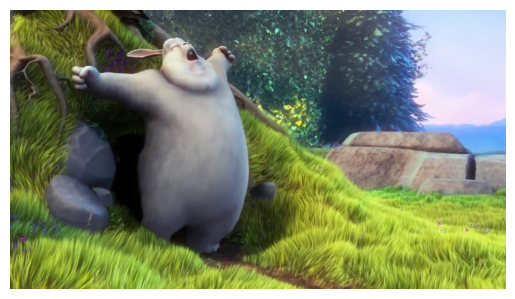

In [4]:
# Carregar o vídeo
video = mp.VideoFileClip("boydancing.mp4")

frame_segundo_3 = video.get_frame(3)
plt.imshow(frame_segundo_3)
plt.axis('off')
plt.show()

**3 -** Aplique detecção de bordas do frame selecionado com treshold de 3 e exiba.

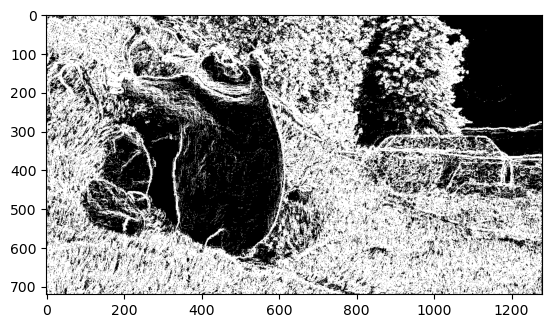

In [8]:
def detectar_bordas(frame, threshold=30):
    l, c, p = frame.shape
    imagem_grey = np.average(frame, axis=2).astype(np.float64)
    
    abs_tg_c = np.abs(np.diff(imagem_grey, axis=0, append=imagem_grey[-1:, :]))
    abs_tg_l = np.abs(np.diff(imagem_grey, axis=1, append=imagem_grey[:, -1:]))
    abs_tg = np.sqrt(abs_tg_c ** 2 + abs_tg_l ** 2)

    imagem_border = np.zeros(shape=(l, c), dtype=np.uint8)
    imagem_border[abs_tg > threshold] = 255
    
    imagem_border_3p = np.stack([imagem_border]*3, axis=-1)
    return imagem_border_3p

plt.imshow(detectar_bordas(frame_segundo_3, 3))

**4 -** Crie uma função que receba um frame e retorne um frame em imagem binário com **treshold de 130**, aplique essa função no vídeo e observe o resultado. **Sua função deve retornar um frame com 3 páginas para evitar problemas**.

In [16]:
def binarizar_frame(frame, thresh=130):
    l, c, p = frame.shape
    image_bw = np.average(frame, axis=2).astype(np.float64)
    image_bin = np.zeros(shape=(l, c), dtype=np.uint8)
    image_bin[image_bw > thresh] = 255
    image_bin_3p = np.stack([image_bin]*3, axis=-1)
    return image_bin_3p

video_binario = video.image_transform(binarizar_frame)
video_binario.display_in_notebook(width=480)

MoviePy - Building video __temp__.mp4.
MoviePy - Writing audio in __temp__TEMP_MPY_wvf_snd.mp3


MoviePy - Done.
MoviePy - Writing video __temp__.mp4



MoviePy - Done !
MoviePy - video ready __temp__.mp4


**5 -** Separe o vídeo original em 2 subclips:
- Segundos 0 ao 2: Aplicar conversão para binário
- Segundos 2 em diante: Mantenha o video original

**Una esses clips em um único vídeo e exiba o resultado.**

In [19]:
subclip_0_2 = video.subclipped(0, 2)
subclip_2_fim = video.subclipped(2) # Vai do segundo 3 até o final

subclip_0_2_binario = subclip_0_2.image_transform(binarizar_frame)

parts = mp.concatenate_videoclips([subclip_0_2_binario, subclip_2_fim])

parts.display_in_notebook(width=480)

MoviePy - Building video __temp__.mp4.
MoviePy - Writing audio in __temp__TEMP_MPY_wvf_snd.mp3


MoviePy - Done.
MoviePy - Writing video __temp__.mp4



MoviePy - Done !
MoviePy - video ready __temp__.mp4


**6 -** Gere um arquivo de áudio contendo uma senoide de 500Hz com duração de 3 segundos, em seguida toque-a.

In [26]:
audio = np.sin(2 * np.pi * 500 * np.linspace(0, 3, 44100 * 3))
Audio(data = audio, rate = 44100)

**7 -** Manipule o áudio da questão anterior de modo que ele fique mais grave.

In [27]:
Audio(data = audio, rate = 22050)

**8 -** Salve o vídeo resultante da questão 5 como "resultado_video.mp4" e o áudio resultante da questão 7 como "resultado_audio

In [28]:
parts.write_videofile('resultado_video.mp4')

MoviePy - Building video resultado_video.mp4.
MoviePy - Writing audio in resultado_videoTEMP_MPY_wvf_snd.mp3


MoviePy - Done.
MoviePy - Writing video resultado_video.mp4



MoviePy - Done !
MoviePy - video ready resultado_video.mp4


In [31]:
audio_save = (audio * 32767).astype(np.int16)
write("resultado_audio.wav", 22050, audio_save)